In [4]:
!pip install xgboost==1.7.6

In [5]:
!pip install scikit-learn==1.4.2

In [6]:
import sklearn
import joblib
import pandas as pd
import xgboost

print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("pandas:", pd.__version__)
print("XGBoost:", xgboost.__version__)

scikit-learn: 1.4.2
joblib: 1.5.3
pandas: 2.3.3
XGBoost: 1.7.6


In [7]:
# Check that the dataset ZIP is available before starting the analysis.
from pathlib import Path
import zipfile
dataset_zip_path = Path("/home/ec2-user/SageMaker/dataset.zip")
if not dataset_zip_path.exists():
    raise FileNotFoundError(
        f"Dataset ZIP was not found at {dataset_zip_path}. "
        "Please upload dataset.zip to /content."
    )
print(f"Dataset found: {dataset_zip_path}")
print(f"File size: {dataset_zip_path.stat().st_size / (1024**3):.2f} GB")

Dataset found: /home/ec2-user/SageMaker/dataset.zip
File size: 1.00 GB


In [8]:
from collections import Counter
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    entries = [entry for entry in zip_file.infolist() if not entry.is_dir()]
extension_counts = Counter(
    Path(entry.filename).suffix.lower() or "[no extension]"
    for entry in entries
)
top_level_counts = Counter(
    entry.filename.split("/")[0]
    for entry in entries
)
print(f"Total files: {len(entries):,}")
print("\nFiles by extension:")
for extension, count in sorted(extension_counts.items()):
    print(f"  {extension}: {count:,}")
print("\nTop level directories:")
for folder, count in sorted(top_level_counts.items()):
    print(f"  {folder}: {count:,} files")

Total files: 3,148

Files by extension:
  .csv: 14
  .ipynb: 6
  .json: 7
  .log: 608
  .md: 1
  .parquet: 2,467
  .png: 19
  .py: 7
  .sample: 13
  .sh: 1
  .txt: 1
  [no extension]: 4

Top level directories:
  .activate.sh: 1 files
  .git: 17 files
  00_raw_datasets: 615 files
  01_aggregated_datasets: 2,476 files
  02_analysis_scripts: 16 files
  03_whole-facility_profiles: 21 files
  README.md: 1 files
  requirements.txt: 1 files


In [9]:
workload_dirs = sorted({
    entry.filename.split("/")[1]
    for entry in entries
    if entry.filename.startswith("00_raw_datasets/")
    and len(entry.filename.split("/")) >= 3
})
print(f"Raw workload directories: {len(workload_dirs)}")
for workload in workload_dirs:
    print(f" - {workload}")

Raw workload directories: 5
 - inference_offline_llama3_70b
 - inference_online_finite_llama3_70b
 - inference_online_rate_llama3_70b
 - training_llama2_70b_lora
 - training_stable_diffusion


In [10]:
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    readme_files = [
        name for name in zip_file.namelist()
        if name.lower().endswith(".md")
    ]
    if not readme_files:
        raise FileNotFoundError("No README Markdown file was found in the ZIP archive.")
    readme_name = readme_files[0]
    readme_text = zip_file.read(readme_name).decode("utf-8", errors="replace")
print(readme_text)

# GenAI Power Profiles Dataset

This repository contains datasets and analysis scripts related to power consumption profiles of generative AI (GenAI) workloads, including both training and inference workloads.

The first version of the dataset includes the following genAI workloads:

- Training or Fine-Tuning:
    - Llamma2 (LLM)
    - Stable Diffusion (Image Generation)
- Inference (Offline and Online)
    - Llamma3 (LLM)

The goal of this dataset is to support data center research in:

- Infrastructure planning  
- Power modeling  
- Energy-aware job scheduling  
- Load forecasting  
- Grid integration studies  

<!-- -------------- -->

## Citation

If you use this dataset, please cite the associated publication: 

> Vercellino et al., “Measurement of Generative AI Workload Power Profiles for Whole-Facility Data Center Infrastructure Planning,” [arXiv:2604.07345](https://arxiv.org/abs/2604.07345) (2026).
 
The original dataset is available via the NLR Data Catalog: https://data.nlr.

In [11]:
import io
import pandas as pd
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    parquet_files = sorted(
        name for name in zip_file.namelist()
        if name.lower().endswith(".parquet")
    )
    parquet_counts = Counter(
        path.split("/")[1]
        for path in parquet_files
    )
    print("Parquet files by workload:")
    for workload, count in sorted(parquet_counts.items()):
        print(f"  {workload}: {count:,}")
    # Select one representative Parquet file from each workload group.
    sample_files = {}
    for path in parquet_files:
        workload = path.split("/")[1]
        sample_files.setdefault(workload, path)
    for workload, path in sorted(sample_files.items()):
        with zip_file.open(path) as file:
            sample_df = pd.read_parquet(io.BytesIO(file.read()))
        print(f"WORKLOAD:{workload}")
        print(f"FILE:{Path(path).name}")
        print(f"Rows:{len(sample_df):,}")
        print(f"Columns:{list(sample_df.columns)}")
        print(sample_df.head(3).to_string())

Parquet files by workload:
  inference_offline_llama3_70b: 1,200
  inference_online_finite_llama3_70b: 1,026
  inference_online_rate_llama3_70b: 200
  training: 41
WORKLOAD:inference_offline_llama3_70b
FILE:000000.parquet
Rows:511
Columns:['power[W]']
                power[W]
timestep[s]             
0.0           792.143065
0.1           991.327360
0.2          1248.529331
WORKLOAD:inference_online_finite_llama3_70b
FILE:000000.parquet
Rows:1,190
Columns:['power[W]']
                power[W]
timestep[s]             
0.0           837.754307
0.1           973.837795
0.2          1072.616736
WORKLOAD:inference_online_rate_llama3_70b
FILE:000000.parquet
Rows:179,955
Columns:['power[W]']
                power[W]
timestep[s]             
0.000        2066.473043
0.001        2066.474635
0.002        2066.476227
WORKLOAD:training
FILE:000000.parquet
Rows:26,601
Columns:['power[W]']
               power[W]
timestep[s]            
0.0          868.775478
0.2          875.796679
0.4          8

In [12]:
import json
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    json_files = sorted(
        name for name in zip_file.namelist()
        if name.lower().endswith(".json")
    )
    print(f"JSON files found: {len(json_files)}")
    for name in json_files:
        print(name)
        try:
            data = json.loads(
                zip_file.read(name).decode("utf-8")
            )
        except json.JSONDecodeError:
            print("Non-standard JSON/JSONL format; skipped for this inspection.")
            continue
        if isinstance(data, dict) and "experiments" in data:
            experiments = data["experiments"]
            print(f"Experiments: {len(experiments)}")
            if experiments:
                print(json.dumps(experiments[0], indent=2))
        elif isinstance(data, list):
            print(f"Records: {len(data)}")
            if data:
                print(f"Fields: {list(data[0].keys())}")
                print(json.dumps(data[0], indent=2))
        else:
            print(json.dumps(data, indent=2))

JSON files found: 7
00_raw_datasets/inference_offline_llama3_70b/config.json
{
  "SLURM_CPUS_ON_NODE": "128",
  "SLURM_GPUS_ON_NODE": "4",
  "SLURM_NODELIST": "x3115c0s33b0n0",
  "model": "/projects/aiuserapps/jwillard/hf_models/Llama-3.1-70B-Instruct"
}
00_raw_datasets/inference_offline_llama3_70b/log.json
Records: 1200
Fields: ['batch_size', 'elapsed', 'end_time', 'max_output_tokens', 'repeat', 'seed', 'start_time']
{
  "batch_size": 550,
  "elapsed": 51.138686,
  "end_time": "2025-09-18_16:31:03.916427",
  "max_output_tokens": 1024,
  "repeat": 0,
  "seed": 2854,
  "start_time": "2025-09-18_16:30:12.777741"
}
00_raw_datasets/inference_online_finite_llama3_70b/config.json
Experiments: 1026
{
  "_repeat": 0,
  "burstiness": 100000,
  "dataset-name": "hf",
  "dataset-path": "likaixin/InstructCoder",
  "hf-output-len": 256,
  "num-prompts": 1000,
  "request_rate": 10,
  "seed": 0
}
00_raw_datasets/inference_online_finite_llama3_70b/log.json
Records: 1026
Fields: ['_repeat', 'burstiness'

In [13]:
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    mapping_checks = {
        "inference_offline_llama3_70b":
            "00_raw_datasets/inference_offline_llama3_70b/log.json",

        "inference_online_finite_llama3_70b":
            "00_raw_datasets/inference_online_finite_llama3_70b/log.json",

        "inference_online_rate_llama3_70b":
            "00_raw_datasets/inference_online_rate_llama3_70b/log.json",
    }
    for workload, log_path in mapping_checks.items():
        log_records = json.loads(
            zip_file.read(log_path).decode("utf-8")
        )
        parquet_count = sum(
            1
            for path in parquet_files
            if f"01_aggregated_datasets/{workload}/results/" in path
        )
        status = "OK" if len(log_records) == parquet_count else "MISMATCH"
        print(
            f"{workload}: "
            f"metadata records={len(log_records):,}, "
            f"Parquet files={parquet_count:,} -> {status}"
        )

inference_offline_llama3_70b: metadata records=1,200, Parquet files=1,200 -> OK
inference_online_finite_llama3_70b: metadata records=1,026, Parquet files=1,026 -> OK
inference_online_rate_llama3_70b: metadata records=200, Parquet files=200 -> OK


In [14]:
metadata_paths = {
    "offline": "01_aggregated_datasets/inference_offline_llama3_70b/metadata.csv",
    "online_finite": "01_aggregated_datasets/inference_online_finite_llama3_70b/metadata.csv",
    "online_rate": "01_aggregated_datasets/inference_online_rate_llama3_70b/metadata.csv",
    "training": "01_aggregated_datasets/training/metadata.csv",
}
metadata = {}
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    for workload, path in metadata_paths.items():
        with zip_file.open(path) as file:
            metadata[workload] = pd.read_csv(file)
        print(f"{workload}:{metadata[workload].shape}")
        print(f"Columns:{list(metadata[workload].columns)}")
        display(metadata[workload].head(3))

offline:(1200, 10)
Columns:['batch_size', 'elapsed', 'end_time', 'max_output_tokens', 'repeat', 'seed', 'start_time', 'path_run', 'peak_power[W]', 'mean_power[W]']


,batch_size,elapsed,end_time,max_output_tokens,repeat,seed,start_time,path_run,peak_power[W],mean_power[W]
0,550,51.138686,2025-09-18 16:31:03.916427,1024,0,2854,2025-09-18 16:30:12.777741,/projects/aiuserapps/genai_power_dataset/01_ag...,3053.759065,2822.104293
1,550,47.384165,2025-09-18 16:31:53.300838,1024,1,2854,2025-09-18 16:31:05.916673,/projects/aiuserapps/genai_power_dataset/01_ag...,3048.839824,2814.350863
2,550,48.965850,2025-09-18 16:32:44.266972,1024,2,2854,2025-09-18 16:31:55.301122,/projects/aiuserapps/genai_power_dataset/01_ag...,3042.525523,2798.014121


online_finite:(1026, 72)
Columns:['_repeat', 'burstiness_x', 'dataset-name', 'dataset-path', 'end_time_exc', 'hf-output-len', 'id', 'num-prompts', 'request_rate_x', 'seed', 'start_time_exc', 'date', 'endpoint_type', 'backend', 'label', 'model_id', 'tokenizer_id', 'num_prompts', 'request_rate_y', 'burstiness_y', 'max_concurrency', 'duration', 'completed', 'total_input_tokens', 'total_output_tokens', 'request_throughput', 'request_goodput', 'output_throughput', 'total_token_throughput', 'max_output_tokens_per_s', 'max_concurrent_requests', 'mean_ttft_ms', 'median_ttft_ms', 'std_ttft_ms', 'p10_ttft_ms', 'p30_ttft_ms', 'p50_ttft_ms', 'p70_ttft_ms', 'p90_ttft_ms', 'mean_tpot_ms', 'median_tpot_ms', 'std_tpot_ms', 'p10_tpot_ms', 'p30_tpot_ms', 'p50_tpot_ms', 'p70_tpot_ms', 'p90_tpot_ms', 'mean_itl_ms', 'median_itl_ms', 'std_itl_ms', 'p10_itl_ms', 'p30_itl_ms', 'p50_itl_ms', 'p70_itl_ms', 'p90_itl_ms', 'mean_e2el_ms', 'median_e2el_ms', 'std_e2el_ms', 'p10_e2el_ms', 'p30_e2el_ms', 'p50_e2el_ms'

,_repeat,burstiness_x,dataset-name,dataset-path,end_time_exc,hf-output-len,id,num-prompts,request_rate_x,seed,...,p90_e2el_ms,start_time_vllm,end_time_vllm,start_time,end_time,run_completed,execution_time_seconds,path_run,peak_power[W],mean_power[W]
0,0,100000,hf,likaixin/InstructCoder,2025-11-30 15:41:52.015074,256,1,1000,10,0,...,5114.628401,2025-11-30 15:41:38,2025-11-30 15:43:22.123269388,2025-11-30 15:39:40.303018,2025-11-30 15:41:52.015074,True,118.9,/projects/aiuserapps/genai_power_dataset/01_ag...,2351.683114,2085.306406
1,0,100000,hf,likaixin/InstructCoder,2025-11-30 15:43:18.318080,256,2,1000,20,0,...,5457.068536,2025-11-30 15:43:18,2025-11-30 15:44:12.522184050,2025-11-30 15:42:12.017302,2025-11-30 15:43:18.318080,True,56.0,/projects/aiuserapps/genai_power_dataset/01_ag...,2348.551505,2265.948935
2,0,100000,hf,likaixin/InstructCoder,2025-11-30 15:44:27.872271,256,3,1000,30,0,...,5892.459001,2025-11-30 15:44:27,2025-11-30 15:45:05.159787518,2025-11-30 15:43:38.320088,2025-11-30 15:44:27.872271,True,39.6,/projects/aiuserapps/genai_power_dataset/01_ag...,2601.319313,2446.739765


online_rate:(200, 15)
Columns:['burstiness', 'dataset-name', 'dataset-path', 'end_time_exc', 'id', 'num-prompts', 'request_rate', 'start_time_exc', 'start_time', 'end_time', 'run_completed', 'execution_time_seconds', 'path_run', 'peak_power[W]', 'mean_power[W]']


,burstiness,dataset-name,dataset-path,end_time_exc,id,num-prompts,request_rate,start_time_exc,start_time,end_time,run_completed,execution_time_seconds,path_run,peak_power[W],mean_power[W]
0,100000,hf,likaixin/InstructCoder,2026-01-05 05:34:32.714319,1,300,1,2026-01-05 05:31:32.714319,2026-01-05 05:31:32.714319,2026-01-05 05:34:32.714319,True,179.954,/projects/aiuserapps/genai_power_dataset/01_ag...,2097.831345,2069.548985
1,100000,hf,likaixin/InstructCoder,2026-01-05 05:39:52.753836,2,600,2,2026-01-05 05:36:52.753836,2026-01-05 05:36:52.753836,2026-01-05 05:39:52.753836,True,179.846,/projects/aiuserapps/genai_power_dataset/01_ag...,2118.523541,2085.325478
2,100000,hf,likaixin/InstructCoder,2026-01-05 05:45:12.801867,3,900,3,2026-01-05 05:42:12.801867,2026-01-05 05:42:12.801867,2026-01-05 05:45:12.801867,True,179.943,/projects/aiuserapps/genai_power_dataset/01_ag...,2140.690436,2088.905829


training:(41, 6)
Columns:['Unnamed: 0', 'model', 'nodes', 'repeat', 'path_save', 'slurmid']


,Unnamed: 0,model,nodes,repeat,path_save,slurmid
0,0,llama2_70b_lora,2,0,training/results/000000.parquet,10742795
1,1,llama2_70b_lora,2,1,training/results/000001.parquet,10742796
2,2,llama2_70b_lora,2,2,training/results/000002.parquet,10742797


In [15]:
training_power_rows = []
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    training_parquet_files = sorted(
        name
        for name in zip_file.namelist()
        if name.startswith("01_aggregated_datasets/training/results/")
        and name.lower().endswith(".parquet")
    )
    for metadata_index, path in enumerate(training_parquet_files):
        with zip_file.open(path) as file:
            power_values = pd.read_parquet(
                io.BytesIO(file.read())
            )["power[W]"]
        training_power_rows.append({
            "metadata_index": metadata_index,
            "mean_power[W]": power_values.mean(),
            "peak_power[W]": power_values.max(),
            "power_samples": len(power_values),
        })
training_power = pd.DataFrame(training_power_rows)
training_metadata = metadata["training"].reset_index(drop=True).copy()
training_metadata["metadata_index"] = training_metadata.index
training_full = (
    training_metadata
    .merge(training_power, on="metadata_index", how="left")
    .drop(columns="metadata_index")
)
assert training_full[
    ["mean_power[W]", "peak_power[W]"]
].notna().all().all()
print(
    f"Training executions: {len(training_full):,} "
    "| Missing power summaries: "
    f"{training_full[['mean_power[W]', 'peak_power[W]']].isna().sum().sum()}"
)
display(training_full.head())

Training executions: 41 | Missing power summaries: 0


,Unnamed: 0,model,nodes,repeat,path_save,slurmid,mean_power[W],peak_power[W],power_samples
0,0,llama2_70b_lora,2,0,training/results/000000.parquet,10742795,5267.813212,6144.482505,26601
1,1,llama2_70b_lora,2,1,training/results/000001.parquet,10742796,5284.503512,6124.141955,29169
2,2,llama2_70b_lora,2,2,training/results/000002.parquet,10742797,5278.125021,6115.386270,26562
3,3,llama2_70b_lora,2,3,training/results/000003.parquet,10742798,5226.846200,6115.803822,26595
4,4,llama2_70b_lora,2,4,training/results/000004.parquet,10742800,5259.117817,6143.958648,26567


In [16]:
raw_sample_paths = [
    "00_raw_datasets/inference_offline_llama3_70b/"
    "nvml_wattameter_x3115c0s33b0n0.log",
    "00_raw_datasets/inference_offline_llama3_70b/"
    "rapl_wattameter_x3115c0s33b0n0.log",
]
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    for path in raw_sample_paths:
        print(path)
        with zip_file.open(path) as file:
            for _ in range(3):
                line = file.readline().decode(
                    "utf-8",
                    errors="replace"
                ).strip()
                print(line[:160])

00_raw_datasets/inference_offline_llama3_70b/nvml_wattameter_x3115c0s33b0n0.log
# 2025-09-18_16:22:44.314867 - Power data for run 10720618
# 2025-09-18_16:22:44.314867 - Tracking started
# timestamp                  reading-time[ns] gpu-0[mW] gpu-1[mW] gpu-2[mW] gpu-3[mW] gpu-0[C] gpu-1[C] gpu-2[C] gpu-3[C]
00_raw_datasets/inference_offline_llama3_70b/rapl_wattameter_x3115c0s33b0n0.log
# 2025-09-18_16:22:44.314867 - Power data for run 10720618
# 2025-09-18_16:22:44.314867 - Tracking started
# timestamp                  reading-time[ns] cpu-0[uJ] cpu-0-core[uJ] cpu-1[uJ] cpu-1-core[uJ] cpu-0[W] cpu-0-core[W] cpu-1[W] cpu-1-core[W]


In [17]:
excluded_fields = {
    "mean_power[W]",
    "peak_power[W]",
    "elapsed",
    "execution_time_seconds",
    "path_run",
    "path_save",
    "slurmid",
    "id",
    "Unnamed: 0",
    "start_time",
    "end_time",
    "start_time_exc",
    "end_time_exc",
    "start_time_vllm",
    "end_time_vllm",
}
for workload in ["offline", "online_finite", "online_rate", "training"]:
    workload_df = (
        training_full
        if workload == "training"
        else metadata[workload]
    )
    varying_fields = [
        (column, workload_df[column].nunique(dropna=True))
        for column in workload_df.columns
        if column not in excluded_fields
        and workload_df[column].nunique(dropna=True) > 1
    ]
    print(f"{workload}: {len(workload_df):,} executions")
    if varying_fields:
        print("Varying configuration fields:")
        for column, unique_values in varying_fields:
            print(f"  {column}: {unique_values} unique values")
    else:
        print("No varying configuration fields found.")

offline: 1,200 executions
Varying configuration fields:
  batch_size: 40 unique values
  max_output_tokens: 2 unique values
  repeat: 3 unique values
  seed: 400 unique values
online_finite: 1,026 executions
Varying configuration fields:
  _repeat: 3 unique values
  dataset-path: 2 unique values
  hf-output-len: 3 unique values
  request_rate_x: 19 unique values
  seed: 3 unique values
  date: 1024 unique values
  request_rate_y: 19 unique values
  duration: 1024 unique values
  total_input_tokens: 6 unique values
  total_output_tokens: 993 unique values
  request_throughput: 1024 unique values
  output_throughput: 1024 unique values
  total_token_throughput: 1024 unique values
  max_output_tokens_per_s: 810 unique values
  max_concurrent_requests: 356 unique values
  mean_ttft_ms: 1024 unique values
  median_ttft_ms: 1024 unique values
  std_ttft_ms: 1024 unique values
  p10_ttft_ms: 1024 unique values
  p30_ttft_ms: 1024 unique values
  p50_ttft_ms: 1024 unique values
  p70_ttft_ms: 

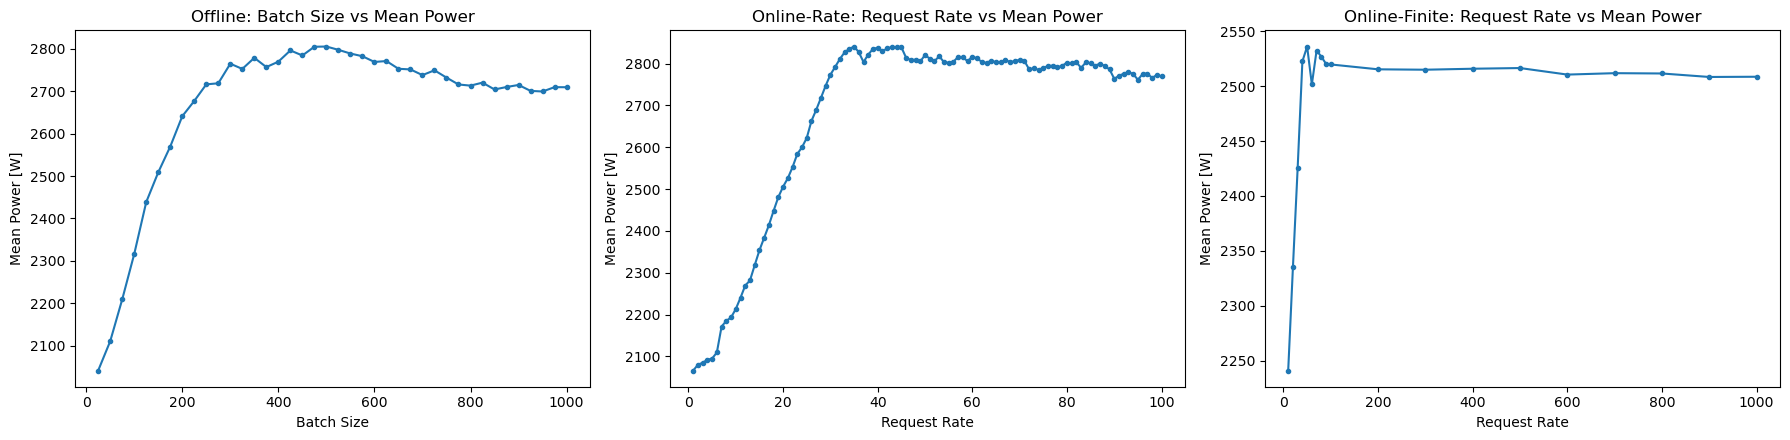

In [18]:
import matplotlib.pyplot as plt
offline_power = (
    metadata["offline"]
    .groupby("batch_size")["mean_power[W]"]
    .mean()
)
online_rate_power = (
    metadata["online_rate"]
    .groupby("request_rate")["mean_power[W]"]
    .mean()
)
online_finite_power = (
    metadata["online_finite"]
    .groupby("request_rate_x")["mean_power[W]"]
    .mean()
)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(
    offline_power.index,
    offline_power.values,
    marker="o",
    markersize=3
)
axes[0].set_title("Offline: Batch Size vs Mean Power")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Mean Power [W]")
axes[1].plot(
    online_rate_power.index,
    online_rate_power.values,
    marker="o",
    markersize=3
)
axes[1].set_title("Online-Rate: Request Rate vs Mean Power")
axes[1].set_xlabel("Request Rate")
axes[1].set_ylabel("Mean Power [W]")
axes[2].plot(
    online_finite_power.index,
    online_finite_power.values,
    marker="o",
    markersize=3
)
axes[2].set_title("Online-Finite: Request Rate vs Mean Power")
axes[2].set_xlabel("Request Rate")
axes[2].set_ylabel("Mean Power [W]")
plt.tight_layout()
plt.show()

In [19]:
online_finite_df = metadata["online_finite"]
low_power_runs = online_finite_df[
    online_finite_df["mean_power[W]"] < 1000
]
display_columns = [
    column
    for column in [
        "id",
        "request_rate_x",
        "hf-output-len",
        "dataset-path",
        "duration",
        "completed",
        "run_completed",
        "mean_power[W]",
    ]
    if column in low_power_runs.columns
]
print(f"Low-power executions identified: {len(low_power_runs)}")
display(low_power_runs[display_columns])
print("\nCompletion status where available:")
for workload in [
    "offline",
    "online_finite",
    "online_rate",
    "training",
]:
    workload_df = (
        training_full
        if workload == "training"
        else metadata[workload]
    )
    if "run_completed" in workload_df.columns:
        print(
            f"  {workload}: "
            f"{workload_df['run_completed'].value_counts().to_dict()}"
        )
    else:
        print(
            f"  {workload}: run_completed field not available "
            f"({len(workload_df):,} executions)"
        )

Low-power executions identified: 2


,id,request_rate_x,hf-output-len,dataset-path,duration,completed,run_completed,mean_power[W]
686,687,30,256,likaixin/InstructCoder,NaN,NaN,False,743.649697
708,709,60,256,mgoin/mlperf-inference-llama2-data,NaN,NaN,False,739.054963



Completion status where available:
  offline: run_completed field not available (1,200 executions)
  online_finite: {True: 1024, False: 2}
  online_rate: {True: 200}
  training: run_completed field not available (41 executions)


In [20]:
# Create a clean execution level dataset for the preprocessing notebook.
# Only valid inference executions and modeling variables are retained.
offline = metadata["offline"].copy()
offline["workload_type"] = "offline_inference"
offline_modeling = offline.rename(
    columns={
        "max_output_tokens": "max_output_tokens",
        "mean_power[W]": "mean_power_w",
    }
)[
    [
        "workload_type",
        "batch_size",
        "max_output_tokens",
        "mean_power_w",
    ]
]
online_finite = metadata["online_finite"].copy()
# Remove the two incomplete executions identified during EDA.
online_finite = online_finite[
    online_finite["run_completed"] == True
].copy()
online_finite["workload_type"] = "online_finite_inference"
online_finite_modeling = online_finite.rename(
    columns={
        "request_rate_x": "request_rate",
        "hf-output-len": "output_length",
        "dataset-path": "dataset",
        "mean_power[W]": "mean_power_w",
    }
)[
    [
        "workload_type",
        "request_rate",
        "output_length",
        "dataset",
        "mean_power_w",
    ]
]
online_rate = metadata["online_rate"].copy()
online_rate["workload_type"] = "online_rate_inference"
online_rate_modeling = online_rate.rename(
    columns={
        "request_rate": "request_rate",
        "dataset-path": "dataset",
        "mean_power[W]": "mean_power_w",
    }
)[
    [
        "workload_type",
        "request_rate",
        "dataset",
        "mean_power_w",
    ]
]
# Combine the three inference workload types.
modeling_dataset = pd.concat(
    [
        offline_modeling,
        online_finite_modeling,
        online_rate_modeling,
    ],
    ignore_index=True
)
print(f"Final modeling dataset shape: {modeling_dataset.shape}")
print("\nWorkload counts:")
print(modeling_dataset["workload_type"].value_counts())
print("\nMissing values:")
print(modeling_dataset.isna().sum())
display(modeling_dataset.head())

Final modeling dataset shape: (2424, 7)

Workload counts:
workload_type
offline_inference          1200
online_finite_inference    1024
online_rate_inference       200
Name: count, dtype: int64

Missing values:
workload_type           0
batch_size           1224
max_output_tokens    1224
mean_power_w            0
request_rate         1200
output_length        1400
dataset              1200
dtype: int64


,workload_type,batch_size,max_output_tokens,mean_power_w,request_rate,output_length,dataset
0,offline_inference,550.0,1024.0,2822.104293,NaN,NaN,NaN
1,offline_inference,550.0,1024.0,2814.350863,NaN,NaN,NaN
2,offline_inference,550.0,1024.0,2798.014121,NaN,NaN,NaN
3,offline_inference,275.0,1024.0,2694.764568,NaN,NaN,NaN
4,offline_inference,275.0,1024.0,2696.992151,NaN,NaN,NaN


In [21]:
from pathlib import Path
dataset_processed_dir = Path(
    "/home/ec2-user/SageMaker/dataset-processed"
)
dataset_processed_dir.mkdir(
    parents=True,
    exist_ok=True
)
modeling_dataset_path = (
    dataset_processed_dir / "inference_modeling_dataset.csv"
)
modeling_dataset.to_csv(
    modeling_dataset_path,
    index=False
)
print(f"Saved modeling dataset to: {modeling_dataset_path}")
print(f"Rows: {len(modeling_dataset):,}")
print(f"Columns: {len(modeling_dataset.columns)}")

Saved modeling dataset to: /home/ec2-user/SageMaker/dataset-processed/inference_modeling_dataset.csv
Rows: 2,424
Columns: 7


In [22]:
import pandas as pd
feature_inventory = pd.DataFrame([
    {"field": "workload_type", "role": "Predictor", "reason": "Distinguishes workload behaviors."},
    {"field": "batch_size", "role": "Predictor", "reason": "Offline inference only; known before execution."},
    {"field": "max_output_tokens", "role": "Predictor", "reason": "Offline inference only; known before execution."},
    {"field": "request_rate", "role": "Predictor", "reason": "Online inference only; configured rate."},
    {"field": "output_length", "role": "Predictor", "reason": "Online-finite only; configured output length."},
    {"field": "dataset", "role": "Predictor", "reason": "Input dataset configuration (online)."},
    {"field": "num_prompts", "role": "Excluded", "reason": "Constant for online-finite; perfectly collinear with request_rate (corr=1.0) for online-rate."},
    {"field": "mean_power[W]", "role": "Target", "reason": "Execution-level mean power."},
    {"field": "peak_power[W]", "role": "Excluded", "reason": "Same-execution power outcome → target leakage."},
    {"field": "elapsed / execution_time_seconds", "role": "Excluded", "reason": "Measured during/after execution."},
    {"field": "throughput / latency metrics", "role": "Excluded", "reason": "Post-execution performance outcomes."},
    {"field": "completed / run_completed", "role": "Filtering only", "reason": "Used to drop incomplete runs, never a predictor."},
    {"field": "id / seed / repeat / path / timestamps / slurmid", "role": "Excluded", "reason": "Identifiers, not workload characteristics."},
])
display(feature_inventory)

,field,role,reason
0,workload_type,Predictor,Distinguishes workload behaviors.
1,batch_size,Predictor,Offline inference only; known before execution.
2,max_output_tokens,Predictor,Offline inference only; known before execution.
3,request_rate,Predictor,Online inference only; configured rate.
4,output_length,Predictor,Online-finite only; configured output length.
5,dataset,Predictor,Input dataset configuration (online).
6,num_prompts,Excluded,Constant for online-finite; perfectly collinea...
7,mean_power[W],Target,Execution-level mean power.
8,peak_power[W],Excluded,Same-execution power outcome → target leakage.
9,elapsed / execution_time_seconds,Excluded,Measured during/after execution.


In [23]:
from pathlib import Path
import pandas as pd
# Load the execution level modeling dataset created by 01_EDA.ipynb.
modeling_dataset_path = Path(
    "/home/ec2-user/SageMaker/dataset-processed/inference_modeling_dataset.csv"
)
if not modeling_dataset_path.exists():
    raise FileNotFoundError(
        f"Modeling dataset not found at: {modeling_dataset_path}"
    )
inference_dataset = pd.read_csv(modeling_dataset_path)
print(f"Dataset shape: {inference_dataset.shape}")
print("\nWorkload counts:")
print(inference_dataset["workload_type"].value_counts().to_string())
print("\nMissing values:")
print(inference_dataset.isna().sum().to_string())
display(inference_dataset.head())

Dataset shape: (2424, 7)

Workload counts:
workload_type
offline_inference          1200
online_finite_inference    1024
online_rate_inference       200

Missing values:
workload_type           0
batch_size           1224
max_output_tokens    1224
mean_power_w            0
request_rate         1200
output_length        1400
dataset              1200


,workload_type,batch_size,max_output_tokens,mean_power_w,request_rate,output_length,dataset
0,offline_inference,550.0,1024.0,2822.104293,NaN,NaN,NaN
1,offline_inference,550.0,1024.0,2814.350863,NaN,NaN,NaN
2,offline_inference,550.0,1024.0,2798.014121,NaN,NaN,NaN
3,offline_inference,275.0,1024.0,2694.764568,NaN,NaN,NaN
4,offline_inference,275.0,1024.0,2696.992151,NaN,NaN,NaN


In [24]:
feature_columns = ["workload_type", "batch_size", "max_output_tokens",
                   "request_rate", "output_length", "dataset"]
target_column = "mean_power_w"
leakage_fields = {
    "mean_power[W]": "target", "peak_power[W]": "same-execution power outcome",
    "elapsed": "execution outcome", "execution_time_seconds": "measured duration",
    "completed": "execution status", "run_completed": "execution status",
    "id": "identifier", "seed": "identifier", "repeat": "identifier",
    "path_run": "identifier", "slurmid": "identifier",
}
leak_in_features = [c for c in leakage_fields if c in feature_columns]
print("Leakage fields in predictors:", leak_in_features or "NONE")
print("Target in predictors:", target_column in feature_columns)
final_dataset = inference_dataset[feature_columns + [target_column]].copy()
assert final_dataset[target_column].notna().all()
print(f"\nFinal dataset: {final_dataset.shape}, target missing: {final_dataset[target_column].isna().sum()}")

Leakage fields in predictors: NONE
Target in predictors: False

Final dataset: (2424, 7), target missing: 0


In [25]:
from sklearn.model_selection import train_test_split
X = final_dataset[feature_columns].copy()
y = final_dataset[target_column].copy()
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=X["workload_type"])
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=X_temp["workload_type"])
for name, part in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{name}: {len(part)} rows | {part['workload_type'].value_counts().to_dict()}")
# No overlap between partitions
assert not (set(X_train.index) & set(X_val.index))
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))
print("Partition overlap: 0 rows everywhere")

train: 1696 rows | {'offline_inference': 840, 'online_finite_inference': 716, 'online_rate_inference': 140}
validation: 364 rows | {'offline_inference': 180, 'online_finite_inference': 154, 'online_rate_inference': 30}
test: 364 rows | {'offline_inference': 180, 'online_finite_inference': 154, 'online_rate_inference': 30}
Partition overlap: 0 rows everywhere


In [26]:
import numpy as np
import joblib
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Define the persistent output directory.
processed_dir = Path(
    "/home/ec2-user/SageMaker/dataset-modeling"
)
processed_dir.mkdir(
    parents=True,
    exist_ok=True
)
# Define feature groups.
categorical_features = [
    "workload_type",
    "dataset",
]
numerical_features = [
    "batch_size",
    "max_output_tokens",
    "request_rate",
    "output_length",
]
# Build the numerical preprocessing pipeline.
numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True,
        ),
    ),
    (
        "scaler",
        StandardScaler(),
    ),
])
# Build the categorical preprocessing pipeline.
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="not_applicable",
        ),
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])
# Combine numerical and categorical preprocessing.
preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features,
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features,
    ),
])
# Fit the preprocessing pipeline on training data ONLY.
preprocessor.fit(X_train)
# Transform all partitions using the fitted training only pipeline.
X_train_p = preprocessor.transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)
# Retrieve the generated feature names.
feature_names = preprocessor.get_feature_names_out()
# Validate that preprocessing produced finite values.
for name, arr in [
    ("train", X_train_p),
    ("validation", X_val_p),
    ("test", X_test_p),
]:
    assert np.isfinite(arr).all(), (
        f"Non-finite values detected in processed {name} data."
    )
# Save the fitted preprocessing pipeline.
preprocessor_path = processed_dir / "preprocessor.joblib"
joblib.dump(
    preprocessor,
    preprocessor_path,
)
print(
    f"Processed shapes: "
    f"train {X_train_p.shape}, "
    f"validation {X_val_p.shape}, "
    f"test {X_test_p.shape}"
)
print(f"\nNumber of processed features:{len(feature_names)}")
print("\nProcessed features:")
for feature in feature_names:
    print(f"-{feature}")
print(f"\nFitted preprocessor saved to:")
print(preprocessor_path)

Processed shapes: train (1696, 14), validation (364, 14), test (364, 14)

Number of processed features:14

Processed features:
-numerical__batch_size
-numerical__max_output_tokens
-numerical__request_rate
-numerical__output_length
-numerical__missingindicator_batch_size
-numerical__missingindicator_max_output_tokens
-numerical__missingindicator_request_rate
-numerical__missingindicator_output_length
-categorical__workload_type_offline_inference
-categorical__workload_type_online_finite_inference
-categorical__workload_type_online_rate_inference
-categorical__dataset_likaixin/InstructCoder
-categorical__dataset_mgoin/mlperf-inference-llama2-data
-categorical__dataset_not_applicable

Fitted preprocessor saved to:
/home/ec2-user/SageMaker/dataset-modeling/preprocessor.joblib


In [27]:
from pathlib import Path
import os
# Save processed datasets to Google Drive for persistence across Colab sessions.
processed_dir = Path(
    "/home/ec2-user/SageMaker/dataset-modeling"
)
processed_dir.mkdir(parents=True, exist_ok=True)
# Features as DataFrames with proper column names; targets as one column frames.
pd.DataFrame(
    X_train_p, columns=feature_names
).to_parquet(processed_dir / "X_train.parquet")
pd.DataFrame(
    X_val_p, columns=feature_names
).to_parquet(processed_dir / "X_validation.parquet")
pd.DataFrame(
    X_test_p, columns=feature_names
).to_parquet(processed_dir / "X_test.parquet")
y_train.to_frame("mean_power_w").to_parquet(
    processed_dir / "y_train.parquet"
)
y_val.to_frame("mean_power_w").to_parquet(
    processed_dir / "y_validation.parquet"
)
y_test.to_frame("mean_power_w").to_parquet(
    processed_dir / "y_test.parquet"
)
# Raw test features plus target, used for per workload evaluation in 03_Modeling.ipynb.
X_test.assign(
    mean_power_w=y_test
).to_parquet(
    processed_dir / "test_raw.parquet"
)
print(f"Saved to: {processed_dir}")
for file_path in sorted(processed_dir.iterdir()):
    print(f"{file_path.name}")

Saved to: /home/ec2-user/SageMaker/dataset-modeling
.ipynb_checkpoints
X_test.parquet
X_train.parquet
X_validation.parquet
preprocessor.joblib
test_raw.parquet
y_test.parquet
y_train.parquet
y_validation.parquet


In [28]:
from pathlib import Path
import pandas as pd
import numpy as np
# Load the processed datasets created by 02_Preprocessing.ipynb.
processed_dir = Path(
    "/home/ec2-user/SageMaker/dataset-modeling"
)
if not processed_dir.exists():
    raise FileNotFoundError(
        f"Processed modeling directory not found: {processed_dir}"
    )
X_train = pd.read_parquet(
    processed_dir / "X_train.parquet"
)
X_val = pd.read_parquet(
    processed_dir / "X_validation.parquet"
)
X_test = pd.read_parquet(
    processed_dir / "X_test.parquet"
)
y_train = pd.read_parquet(
    processed_dir / "y_train.parquet"
)["mean_power_w"]
y_val = pd.read_parquet(
    processed_dir / "y_validation.parquet"
)["mean_power_w"]
y_test = pd.read_parquet(
    processed_dir / "y_test.parquet"
)["mean_power_w"]
test_raw = pd.read_parquet(
    processed_dir / "test_raw.parquet"
)
print(
    f"Train:{X_train.shape}"
    f"\nValidation:{X_val.shape}"
    f"\nTest:{X_test.shape}"
)
print(f"\nProcessed feature count: {X_train.shape[1]}")
print(f"Target: mean_power_w")

Train:(1696, 14)
Validation:(364, 14)
Test:(364, 14)

Processed feature count: 14
Target: mean_power_w


In [29]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
def evaluate(model, X, y, label):
    """Evaluate a regression model and return standard metrics."""
    predictions = model.predict(X)
    rmse = mean_squared_error(y, predictions) ** 0.5
    mae = mean_absolute_error(y, predictions)
    r2 = r2_score(y, predictions)
    mae_relative = mae / y.mean()
    print(
        f"{label:30s} "
        f"RMSE={rmse:8.2f} W | "
        f"MAE={mae:8.2f} W | "
        f"R²={r2:6.4f} | "
        f"MAE/mean={mae_relative:.2%}"
    )
    return {
        "model": label,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
    }

In [30]:
from sklearn.dummy import DummyRegressor
results = []
# Baseline 1: predict the overall training set mean.
global_mean = DummyRegressor(
    strategy="mean"
).fit(
    X_train,
    y_train
)
results.append(
    evaluate(
        global_mean,
        X_val,
        y_val,
        "Baseline: global mean"
    )
)
# Baseline 2: predict the training set mean for each workload type.
workload_cols = [
    column
    for column in X_train.columns
    if column.startswith("categorical__workload_type_")
]
train_workload = (
    X_train[workload_cols]
    .idxmax(axis=1)
    .str.replace(
        "categorical__workload_type_",
        "",
        regex=False,
    )
)
workload_means = (
    y_train.groupby(train_workload.values)
    .mean()
)
class WorkloadMeanPredictor:
    """Predict the training set mean power for each workload type."""
    def predict(self, X):
        workload = (
            X[workload_cols]
            .idxmax(axis=1)
            .str.replace(
                "categorical__workload_type_",
                "",
                regex=False,
            )
        )
        return (
            workload
            .map(workload_means)
            .fillna(y_train.mean())
            .values
        )
workload_mean = WorkloadMeanPredictor()
results.append(
    evaluate(
        workload_mean,
        X_val,
        y_val,
        "Baseline: workload mean"
    )
)

Baseline: global mean          RMSE=  187.11 W | MAE=  150.29 W | R²=-0.0002 | MAE/mean=5.79%
Baseline: workload mean        RMSE=  167.52 W | MAE=  115.37 W | R²=0.1983 | MAE/mean=4.44%


In [31]:
from sklearn.linear_model import LinearRegression
linear_regression = LinearRegression().fit(
    X_train,
    y_train
)
results.append(
    evaluate(
        linear_regression,
        X_val,
        y_val,
        "Linear Regression"
    )
)

Linear Regression              RMSE=  146.84 W | MAE=  106.59 W | R²=0.3840 | MAE/mean=4.11%


In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
random_forest = RandomForestRegressor(
    random_state=42,
    n_jobs=-1,
)
random_forest_params = {
    "n_estimators": [300, 500, 800],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
}
random_forest_search = RandomizedSearchCV(
    estimator=random_forest,
    param_distributions=random_forest_params,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
random_forest_search.fit(
    X_train,
    y_train,
)
print(
    f"Best parameters: "
    f"{random_forest_search.best_params_}"
)
print(
    f"Best CV RMSE: "
    f"{-random_forest_search.best_score_:.2f} W"
)
results.append(
    evaluate(
        random_forest_search.best_estimator_,
        X_val,
        y_val,
        "Random Forest (tuned)"
    )
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}
Best CV RMSE: 39.72 W
Random Forest (tuned)          RMSE=   37.20 W | MAE=   24.74 W | R²=0.9605 | MAE/mean=0.95%


In [33]:
from xgboost import XGBRegressor
xgboost_model = XGBRegressor(
    random_state=42,
    n_jobs=-1,
)
xgboost_params = {
    "n_estimators": [500, 1000, 2000],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 4, 6, 8],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_lambda": [0.1, 1.0, 10.0],
}
xgboost_search = RandomizedSearchCV(
    estimator=xgboost_model,
    param_distributions=xgboost_params,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
xgboost_search.fit(
    X_train,
    y_train,
)
print(
    f"Best parameters: "
    f"{xgboost_search.best_params_}"
)
print(
    f"Best CV RMSE: "
    f"{-xgboost_search.best_score_:.2f} W"
)
results.append(
    evaluate(
        xgboost_search.best_estimator_,
        X_val,
        y_val,
        "XGBoost (tuned)"
    )
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'subsample': 1.0, 'reg_lambda': 0.1, 'n_estimators': 1000, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Best CV RMSE: 39.27 W
XGBoost (tuned)                RMSE=   37.25 W | MAE=   25.27 W | R²=0.9604 | MAE/mean=0.97%


In [34]:
# Compare all candidate models using the validation set.
comparison = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)
display(comparison)
# Store every candidate model so the model selected from the
# validation results is always the model that is actually evaluated.
candidate_models = {
    "Baseline: global mean": global_mean,
    "Baseline: workload mean": workload_mean,
    "Linear Regression": linear_regression,
    "Random Forest (tuned)": random_forest_search.best_estimator_,
    "XGBoost (tuned)": xgboost_search.best_estimator_,
}
# Select the model with the lowest validation RMSE.
best_name = comparison.iloc[0]["model"]
best_model = candidate_models[best_name]
print(f"\nBest model on validation: {best_name}")

,model,RMSE,MAE,R2
0,Random Forest (tuned),37.196192,24.740965,0.960473
1,XGBoost (tuned),37.249581,25.273876,0.960360
2,Linear Regression,146.839116,106.585422,0.384005
3,Baseline: workload mean,167.521414,115.370299,0.198258
4,Baseline: global mean,187.113614,150.288525,-0.000241



Best model on validation: Random Forest (tuned)


In [35]:
test_metrics = evaluate(
    best_model,
    X_test,
    y_test,
    f"TEST: {best_name}"
)

TEST: Random Forest (tuned)    RMSE=   37.61 W | MAE=   25.10 W | R²=0.9599 | MAE/mean=0.97%


In [36]:
predictions = best_model.predict(X_test)
per_workload = []
for workload_type in sorted(
    test_raw["workload_type"].unique()
):
    mask = (
        test_raw["workload_type"] == workload_type
    ).values
    per_workload.append({
        "workload_type": workload_type,
        "n": int(mask.sum()),
        "RMSE": (
            mean_squared_error(
                y_test[mask],
                predictions[mask],
            ) ** 0.5
        ),
        "MAE": mean_absolute_error(
            y_test[mask],
            predictions[mask],
        ),
        "R2": r2_score(
            y_test[mask],
            predictions[mask],
        ),
    })
per_workload_results = pd.DataFrame(
    per_workload
)
display(per_workload_results)

,workload_type,n,RMSE,MAE,R2
0,offline_inference,180,40.789619,23.243548,0.953376
1,online_finite_inference,154,36.700295,29.856282,0.878908
2,online_rate_inference,30,16.279240,11.789266,0.994520


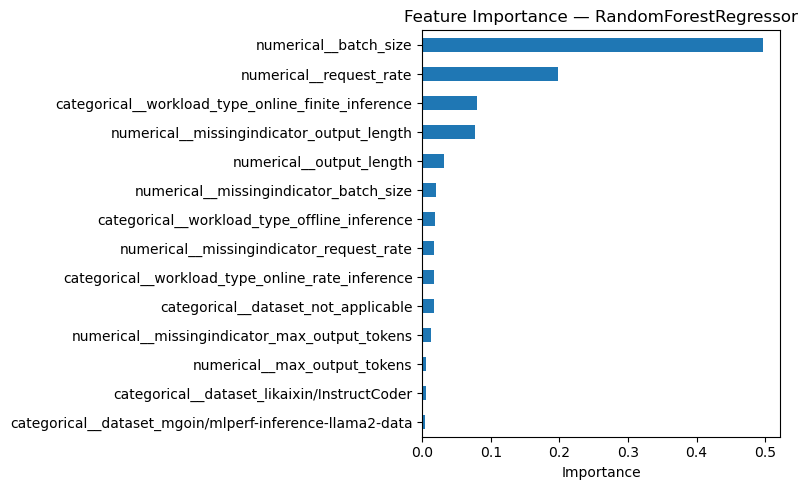

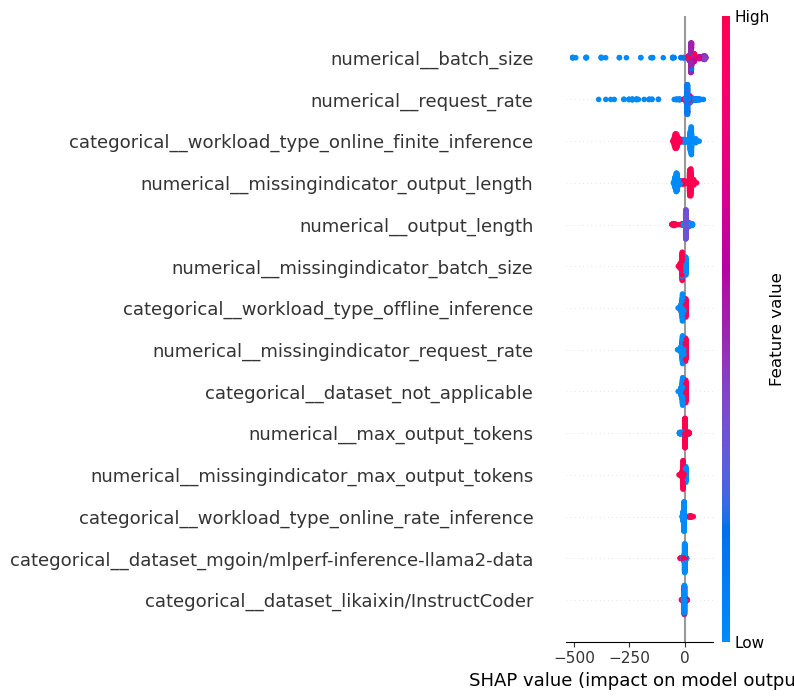

In [37]:
import matplotlib.pyplot as plt
# Feature importance is available for tree-based models.
if hasattr(best_model, "feature_importances_"):
    importance = (
        pd.Series(
            best_model.feature_importances_,
            index=X_train.columns,
        )
        .sort_values()
    )
    ax = importance.plot.barh(
        figsize=(8, 5),
        title=(
            f"Feature Importance — "
            f"{type(best_model).__name__}"
        ),
    )
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print(
        "The selected model does not provide "
        "built in feature importances."
    )
# Attempt SHAP analysis for tree based models.
try:
    import shap
    if hasattr(best_model, "feature_importances_"):
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(
            X_test
        )
        shap.summary_plot(
            shap_values,
            X_test,
            feature_names=X_train.columns.tolist(),
            show=False,
        )
        plt.tight_layout()
        plt.show()
    else:
        print(
            "SHAP tree explanations are skipped "
            "because the selected model is not tree based."
        )
except ImportError:
    print(
        "SHAP is not installed. "
        "Install it with `pip install shap` if needed."
    )

In [38]:
import joblib
model_path = processed_dir / "best_model.joblib"
model_artifact = {
    "model": best_model,
    "feature_names": X_train.columns.tolist(),
    "validation_metrics": comparison.iloc[0].to_dict(),
}
joblib.dump(
    model_artifact,
    model_path,
)
print(
    f"Selected model saved to:\n{model_path}"
)
print(
    f"\nSelected model: {best_name}"
)

Selected model saved to:
/home/ec2-user/SageMaker/dataset-modeling/best_model.joblib

Selected model: Random Forest (tuned)


In [39]:
# Deployment preparation: verify that the selected model artifact and fitted preprocessor exist and can be loaded.
from pathlib import Path
import joblib

artifact_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")

model_path = artifact_dir / "best_model.joblib"
preprocessor_path = artifact_dir / "preprocessor.joblib"

print("Model exists:", model_path.exists())
print("Preprocessor exists:", preprocessor_path.exists())

best_model = joblib.load(model_path)
preprocessor = joblib.load(preprocessor_path)

print("\nModel type:", type(best_model))
print("Preprocessor type:", type(preprocessor))

Model exists: True
Preprocessor exists: True

Model type: <class 'dict'>
Preprocessor type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [40]:
# Inspect the selected model and confirm the preprocessor's transformed feature names and count.
# The Random Forest is trained on 14 transformed features, not the six raw request fields.
print("Model:", best_model)

if hasattr(preprocessor, "get_feature_names_out"):
    feature_names = preprocessor.get_feature_names_out()
    print("\nNumber of processed features:", len(feature_names))
    print("Feature names:")
    print(list(feature_names))

print("\nModel input features:",
      getattr(best_model, "n_features_in_", "Not exposed"))

Model: {'model': RandomForestRegressor(max_depth=10, max_features='log2', n_estimators=300,
                      n_jobs=-1, random_state=42), 'feature_names': ['numerical__batch_size', 'numerical__max_output_tokens', 'numerical__request_rate', 'numerical__output_length', 'numerical__missingindicator_batch_size', 'numerical__missingindicator_max_output_tokens', 'numerical__missingindicator_request_rate', 'numerical__missingindicator_output_length', 'categorical__workload_type_offline_inference', 'categorical__workload_type_online_finite_inference', 'categorical__workload_type_online_rate_inference', 'categorical__dataset_likaixin/InstructCoder', 'categorical__dataset_mgoin/mlperf-inference-llama2-data', 'categorical__dataset_not_applicable'], 'validation_metrics': {'model': 'Random Forest (tuned)', 'RMSE': 37.19619247477418, 'MAE': 24.740965028429606, 'R2': 0.9604732640635285}}

Number of processed features: 14
Feature names:
['numerical__batch_size', 'numerical__max_output_tokens', 'n

In [41]:
# Artifact consistency check: extract the estimator from the saved dictionary and confirm feature order.
# Recompute test metrics from the saved estimator using the already-preprocessed held-out test matrix.

import joblib
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

artifact_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")

saved_artifact = joblib.load(artifact_dir / "best_model.joblib")
preprocessor = joblib.load(artifact_dir / "preprocessor.joblib")

# Extract the actual Random Forest from the saved dictionary
rf_model = saved_artifact["model"]
saved_feature_names = saved_artifact["feature_names"]

# Confirm the preprocessor's output feature order
processed_feature_names = list(preprocessor.get_feature_names_out())

assert saved_feature_names == processed_feature_names, (
    "Feature names or order do not match!"
)

assert X_test.shape[1] == len(saved_feature_names), (
    "X_test has an unexpected number of features!"
)

# Predict directly from the already-preprocessed test matrix
y_test_pred = rf_model.predict(X_test)

print("Model type:", type(rf_model).__name__)
print("Number of features:", len(saved_feature_names))
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_test_pred)):.2f} W")
print(f"Test MAE:  {mean_absolute_error(y_test, y_test_pred):.2f} W")
print(f"Test R²:   {r2_score(y_test, y_test_pred):.4f}")

Model type: RandomForestRegressor
Number of features: 14
Test RMSE: 37.61 W
Test MAE:  25.10 W
Test R²:   0.9599


In [42]:
# Record the software versions used in this notebook; version alignment matters when loading joblib artifacts.
import sklearn
import joblib
import sagemaker

print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("SageMaker SDK:", sagemaker.__version__)

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


/home/ec2-user/anaconda3/envs/pytorch/lib/python3.10/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


scikit-learn: 1.4.2
joblib: 1.5.3
SageMaker SDK: 2.257.6


In [43]:
# Resolve the SageMaker execution role, AWS region, and default S3 bucket for deployment resources.
import sagemaker
import boto3

session = sagemaker.Session()
role = sagemaker.get_execution_role()
region = boto3.Session().region_name

print("Region:", region)
print("SageMaker session bucket:", session.default_bucket())
print("Execution role:", role)

Region: us-east-1
SageMaker session bucket: sagemaker-us-east-1-451813790848
Execution role: arn:aws:iam::451813790848:role/LabRole


In [45]:
# Inspect the fitted preprocessor's raw input schema (six columns) and transformed output width (14 features).
import joblib
from pathlib import Path

base_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")
preprocessor = joblib.load(base_dir / "preprocessor.joblib")

print("Expected raw input columns:")
print(list(preprocessor.feature_names_in_))

print("\nNumber of raw input columns:")
print(len(preprocessor.feature_names_in_))

print("\nOutput feature count:")
print(len(preprocessor.get_feature_names_out()))

Expected raw input columns:
['workload_type', 'batch_size', 'max_output_tokens', 'request_rate', 'output_length', 'dataset']

Number of raw input columns:
6

Output feature count:
14


In [49]:
# Discover which managed scikit-learn inference image versions are recognized by this SageMaker SDK.
# The selected image below is the 1.4-2 container, matching scikit-learn 1.4.2.
import sagemaker
from sagemaker import image_uris

print("SageMaker SDK:", sagemaker.__version__)

for version in ["1.7-1", "1.4-2"]:
    try:
        uri = image_uris.retrieve(
            framework="sklearn",
            region="us-east-1",
            version=version
        )
        print(f"scikit-learn container {version}: {uri}")
    except Exception as e:
        print(f"Container {version} unavailable:", str(e)[:250])

SageMaker SDK: 2.257.6
Container 1.7-1 unavailable: Unsupported sklearn version: 1.7-1. You may need to upgrade your SDK version (pip install -U sagemaker) for newer sklearn versions. Supported sklearn version(s): 0.20.0, 0.23-1, 1.0-1, 1.2-1, 1.4-2.
scikit-learn container 1.4-2: 683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-scikit-learn:1.4-2-cpu-py3


In [51]:
# Confirm that the regenerated artifacts exist under the expected SageMaker path and inspect saved validation metrics.
import sklearn
import joblib
from pathlib import Path

base_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")

print("scikit-learn:", sklearn.__version__)

for name in ["best_model.joblib", "preprocessor.joblib"]:
    path = base_dir / name
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

saved = joblib.load(base_dir / "best_model.joblib")
print("Saved model:", type(saved["model"]).__name__)
print("Validation metrics:", saved.get("validation_metrics"))

scikit-learn: 1.4.2
best_model.joblib: FOUND
preprocessor.joblib: FOUND
Saved model: RandomForestRegressor
Validation metrics: {'model': 'Random Forest (tuned)', 'RMSE': 37.19619247477418, 'MAE': 24.740965028429606, 'R2': 0.9604732640635285}


In [52]:
# Confirm the saved artifact structure and the raw input/output feature dimensions before packaging.
import joblib
from pathlib import Path

base_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")

model_obj = joblib.load(base_dir / "best_model.joblib")
preprocessor = joblib.load(base_dir / "preprocessor.joblib")

print("Model object type:", type(model_obj).__name__)
print("Preprocessor inputs:", list(preprocessor.feature_names_in_))
print("Processed feature count:", len(preprocessor.get_feature_names_out()))

Model object type: dict
Preprocessor inputs: ['workload_type', 'batch_size', 'max_output_tokens', 'request_rate', 'output_length', 'dataset']
Processed feature count: 14


In [53]:
# Create the custom inference handler and deployment copies of the estimator and preprocessor.
# The handler accepts raw JSON records, applies the fitted preprocessor once, and returns predicted mean power in watts.
from pathlib import Path

base_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")
deploy_dir = base_dir / "rf-inference-code"
deploy_dir.mkdir(exist_ok=True)

inference_code = r'''
import os
import json
import joblib
import pandas as pd

def model_fn(model_dir):
    model = joblib.load(os.path.join(model_dir, "model.joblib"))
    preprocessor = joblib.load(os.path.join(model_dir, "preprocessor.joblib"))
    return {"model": model, "preprocessor": preprocessor}

def input_fn(request_body, content_type):
    if content_type != "application/json":
        raise ValueError("Content-Type must be application/json")
    payload = json.loads(request_body)
    records = payload["instances"] if isinstance(payload, dict) else payload
    return pd.DataFrame(records)

def predict_fn(data, artifacts):
    preprocessor = artifacts["preprocessor"]
    model = artifacts["model"]
    expected = list(preprocessor.feature_names_in_)
    missing = [c for c in expected if c not in data.columns]
    if missing:
        raise ValueError(f"Missing raw input columns: {missing}")
    transformed = preprocessor.transform(data[expected])
    return {
        "predicted_mean_power_w": [
            float(v) for v in model.predict(transformed)
        ]
    }

def output_fn(prediction, accept):
    return json.dumps(prediction), "application/json"
'''

(deploy_dir / "inference.py").write_text(inference_code)

import joblib
job = joblib.load(base_dir / "best_model.joblib")
rf_model = job["model"]
preprocessor = joblib.load(base_dir / "preprocessor.joblib")

joblib.dump(rf_model, deploy_dir / "model.joblib")
joblib.dump(preprocessor, deploy_dir / "preprocessor.joblib")

print("Prepared model, preprocessor and inference script.")

Prepared model, preprocessor and inference script.


In [54]:
# Bundle the model estimator, preprocessor, and inference handler into model.tar.gz for SageMaker to download.
import tarfile

archive_path = base_dir / "model.tar.gz"

with tarfile.open(archive_path, "w:gz") as tar:
    for name in ["model.joblib", "preprocessor.joblib", "inference.py"]:
        tar.add(deploy_dir / name, arcname=name)

print("Archive:", archive_path)
print("Size:", f"{archive_path.stat().st_size:,} bytes")

Archive: /home/ec2-user/SageMaker/dataset-modeling/model.tar.gz
Size: 2,322,666 bytes


In [55]:
# Upload the model archive to S3; SageMaker references this S3 URI when creating the model resource.
import boto3
from pathlib import Path

region = "us-east-1"
bucket = "sagemaker-us-east-1-451813790848"
s3_key = "prj-inference-power-feature-store/model/random-forest/model.tar.gz"

archive_path = Path(
    "/home/ec2-user/SageMaker/dataset-modeling/model.tar.gz"
)

s3 = boto3.client("s3", region_name=region)

s3.upload_file(
    str(archive_path),
    bucket,
    s3_key
)

model_data = f"s3://{bucket}/{s3_key}"
print("Model package uploaded:", model_data)

Model package uploaded: s3://sagemaker-us-east-1-451813790848/prj-inference-power-feature-store/model/random-forest/model.tar.gz


In [59]:
# Upload inference.py separately as a source archive for the managed scikit-learn serving container.
# The resulting source_uri is referenced in the model's environment configuration in the next cell.
import tarfile
import boto3
from pathlib import Path

base_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")
deploy_dir = base_dir / "rf-inference-code"

source_archive = base_dir / "rf-inference-source.tar.gz"

# The source archive contains inference.py at its root.
with tarfile.open(source_archive, "w:gz") as tar:
    tar.add(deploy_dir / "inference.py", arcname="inference.py")

bucket = "sagemaker-us-east-1-451813790848"
source_key = "prj-inference-power-feature-store/model/random-forest/rf-inference-source.tar.gz"

s3 = boto3.client("s3", region_name="us-east-1")
s3.upload_file(str(source_archive), bucket, source_key)

source_uri = f"s3://{bucket}/{source_key}"
print("Inference source uploaded:", source_uri)

Inference source uploaded: s3://sagemaker-us-east-1-451813790848/prj-inference-power-feature-store/model/random-forest/rf-inference-source.tar.gz


In [60]:
# Create a SageMaker model resource using the managed scikit-learn 1.4-2 image, S3 model artifact, and inference source archive.
# This creates a model definition only; it does not start endpoint hosting by itself.
import boto3
import sagemaker
from sagemaker import image_uris

region = "us-east-1"
role = sagemaker.get_execution_role()
sm = boto3.client("sagemaker", region_name=region)

image_uri = image_uris.retrieve(
    framework="sklearn",
    region=region,
    version="1.4-2",
    py_version="py3",
    instance_type="ml.m5.large",
)

bucket = "sagemaker-us-east-1-451813790848"
model_data = (
    f"s3://{bucket}/prj-inference-power-feature-store/"
    "model/random-forest/model.tar.gz"
)

model_name = "rf-power-prediction-142-v2"

sm.create_model(
    ModelName=model_name,
    ExecutionRoleArn=role,
    PrimaryContainer={
        "Image": image_uri,
        "ModelDataUrl": model_data,
        "Environment": {
            "SAGEMAKER_PROGRAM": "inference.py",
            "SAGEMAKER_SUBMIT_DIRECTORY": source_uri,
        },
    },
)

print("Created model:", model_name)
print("Image:", image_uri)

Created model: rf-power-prediction-142-v2
Image: 683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-scikit-learn:1.4-2-cpu-py3


In [61]:
# Diagnostic check for the created model
import boto3

sm = boto3.client("sagemaker", region_name="us-east-1")

response = sm.describe_model(
    ModelName="rf-power-prediction-142"
)

print("Model:", response["ModelName"])
print("Image:", response["PrimaryContainer"]["Image"])
print("Artifact:", response["PrimaryContainer"]["ModelDataUrl"])
print("Role:", response["ExecutionRoleArn"])

Model: rf-power-prediction-142
Image: 683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-scikit-learn:1.4-2-cpu-py3
Artifact: s3://sagemaker-us-east-1-451813790848/prj-inference-power-feature-store/model/random-forest/model.tar.gz
Role: arn:aws:iam::451813790848:role/LabRole


In [62]:
# Create an endpoint configuration and endpoint for the Random Forest model.
# This endpoint uses one ml.m5.large instance.
import boto3
import time

region = "us-east-1"
sm = boto3.client("sagemaker", region_name=region)

model_name = "rf-power-prediction-142-v2"
endpoint_config_name = "rf-power-prediction-config-v2"
endpoint_name = "rf-power-prediction-142-v2"

# Create endpoint configuration
sm.create_endpoint_config(
    EndpointConfigName=endpoint_config_name,
    ProductionVariants=[
        {
            "VariantName": "AllTraffic",
            "ModelName": model_name,
            "InitialInstanceCount": 1,
            "InstanceType": "ml.m5.large",
            "InitialVariantWeight": 1.0,
        }
    ],
)

print("Endpoint configuration created:", endpoint_config_name)

# Create endpoint
sm.create_endpoint(
    EndpointName=endpoint_name,
    EndpointConfigName=endpoint_config_name,
)

print("Endpoint creation started:", endpoint_name)

Endpoint configuration created: rf-power-prediction-config-v2
Endpoint creation started: rf-power-prediction-142-v2


In [63]:
# Check if the Endpoint becomes Active
import boto3
import time

sm = boto3.client("sagemaker", region_name="us-east-1")
endpoint_name = "rf-power-prediction-142-v2"

while True:
    response = sm.describe_endpoint(EndpointName=endpoint_name)
    status = response["EndpointStatus"]
    print("Endpoint status:", status)

    if status in ("InService", "Failed", "OutOfService"):
        if status == "Failed":
            print("Failure reason:", response.get("FailureReason"))
        break

    time.sleep(30)

Endpoint status: Creating
Endpoint status: Creating
Endpoint status: Creating
Endpoint status: Creating
Endpoint status: Creating
Endpoint status: Creating
Endpoint status: InService


In [64]:
# Smoke test: invoke the live endpoint with one example raw workload record to verify request/response handling.
# This is a functional check, not an accuracy evaluation.
import boto3
import json

runtime = boto3.client("sagemaker-runtime", region_name="us-east-1")

endpoint_name = "rf-power-prediction-142-v2"

sample = {
    "instances": [
        {
            "workload_type": "offline_inference",
            "batch_size": 1,
            "max_output_tokens": 128,
            "request_rate": None,
            "output_length": 100,
            "dataset": "not_applicable"
        }
    ]
}

response = runtime.invoke_endpoint(
    EndpointName=endpoint_name,
    ContentType="application/json",
    Body=json.dumps(sample)
)

result = json.loads(response["Body"].read().decode("utf-8"))
print("Live prediction:", result)

Live prediction: {'predicted_mean_power_w': [2142.5102202131675]}


In [65]:
# End-to-end consistency check: send a held-out raw test row to the notebook model and live endpoint.
# Matching predictions verify that preprocessing and model inference are aligned for this example.

import boto3
import json
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

base_dir = Path("/home/ec2-user/SageMaker/dataset-modeling")
endpoint_name = "rf-power-prediction-142-v2"

# Load regenerated artifacts
saved = joblib.load(base_dir / "best_model.joblib")
rf_model = saved["model"]
preprocessor = joblib.load(base_dir / "preprocessor.joblib")

# Read one held-out raw test example
test_raw = pd.read_parquet(base_dir / "test_raw.parquet")
raw_columns = list(preprocessor.feature_names_in_)
sample = test_raw[raw_columns].iloc[[0]]

# Notebook prediction: preprocess raw inputs, then predict
X_sample = preprocessor.transform(sample)
notebook_prediction = float(rf_model.predict(X_sample)[0])

# Endpoint prediction: send the exact same raw inputs
runtime = boto3.client("sagemaker-runtime", region_name="us-east-1")
payload = {"instances": sample.astype(object).where(
    pd.notna(sample), None
).to_dict(orient="records")}

response = runtime.invoke_endpoint(
    EndpointName=endpoint_name,
    ContentType="application/json",
    Body=json.dumps(payload)
)

endpoint_result = json.loads(response["Body"].read().decode("utf-8"))
endpoint_prediction = float(
    endpoint_result["predicted_mean_power_w"][0]
)

print("Notebook prediction:", round(notebook_prediction, 4), "W")
print("Endpoint prediction:", round(endpoint_prediction, 4), "W")
print("Absolute difference:", round(abs(
    notebook_prediction - endpoint_prediction
), 6), "W")

/home/ec2-user/anaconda3/envs/pytorch/lib/python3.10/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Notebook prediction: 2258.6723 W
Endpoint prediction: 2258.6723 W
Absolute difference: 0.0 W
